# Урок 12. Как у мягкого шарика появляются собственные оси

[Программа курса](../../README_ru.md)

У точки из прошлого урока нет ширины. Из любого положения камеры она даёт один адрес. Теперь вокруг неё появится мягкое облачко. На равном весе у круглого облачка получится сфера. Если потянуть его за один край и повернуть целиком, та же линия равного веса превратится в поверхность вытянутого эллипсоида.

In [1]:
%matplotlib inline
from pathlib import Path
import sys

course = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "geometry3d.py").is_file())
if str(course) not in sys.path:
    sys.path.insert(0, str(course))

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
import geometry3d as geo
import geometry_demos as demos
np.set_printoptions(precision=4, suppress=True)

## 1. Три размера одного облачка

Оба рисунка показывают одну проволочную поверхность. Справа мы смотрим вдоль $z$, слева — под углом. Это пока чертежи без перспективы. Цветные отрезки идут из центра до поверхности вдоль её собственных осей. У оранжевого сначала длина 2 м, у зелёного 0.75 м, у фиолетового 1 м. Когда угол меняется, концы отрезков переезжают. Их длины сохраняются.

При трёх одинаковых масштабах получается шар. Можно развернуть его на любой угол: цветные отрезки повернутся, геометрический контур совпадёт с прежним. Если один масштаб длиннее, только некоторые повороты сохранят силуэт. Таблица под рисунком связывает наблюдение с числами формы.

In [2]:
display(demos.geometry_lab(12, "ru"))

## 2. Как вычислить вес и нарисовать поверхность

Пока оси совпадают с мировыми. Пусть центр $\mu=(0,0,0)$ м, а масштабы $s_x=2$, $s_y=0.75$, $s_z=1$ м. По каждой оси мы сначала вычитаем центр и делим на **её** масштаб. Для точки $(2,0,0)$ получатся числа $(2/2,0/0.75,0/1)=(1,0,0)$, уже без единиц. Для $(0,0.75,0)$ выйдет $(0,1,0)$. В обоих случаях сумма квадратов равна 1. Значит, вес из урока 3 совпадает, хотя расстояния в метрах разные:

$$
D^2=h_x^2+h_y^2+h_z^2,\qquad G=\exp(-D^2/2)=\exp(-1/2)\approx0.607.
$$

Здесь $h$ — три относительных смещения, $D^2$ измеряет квадрат удалённости в масштабе облачка, а $G$ — относительный вес с максимумом 1 в центре. Рисунок соединяет только точки $D^2=1$. За проволокой вес продолжает убывать; жёсткой границы у облачка нет.

Для построения поверхности расчёт удобно обратить. На единичной сфере берём точку $h=(0.6,0.8,0)$, ведь $0.6^2+0.8^2=1$. По своим осям умножаем на масштабы: $(1.2,0.6,0)$ м. Затем следует поворот $R$, и уже после него добавляется центр. Короткая запись $P=\mu+RSh$ использует диагональную матрицу $S$. По диагонали стоят три масштаба, все остальные числа нули. Умножение на неё как раз даёт $(s_x h_x,s_y h_y,s_z h_z)$.

In [3]:
scales = np.array([2., .75, 1.])
h = np.array([.6, .8, 0.])
print("Sh =", scales*h, "m; G =", np.exp(-(h @ h)/2))
assert np.isclose(h @ h, 1)

Sh = [1.2 0.6 0. ] m; G = 0.6065306597126334


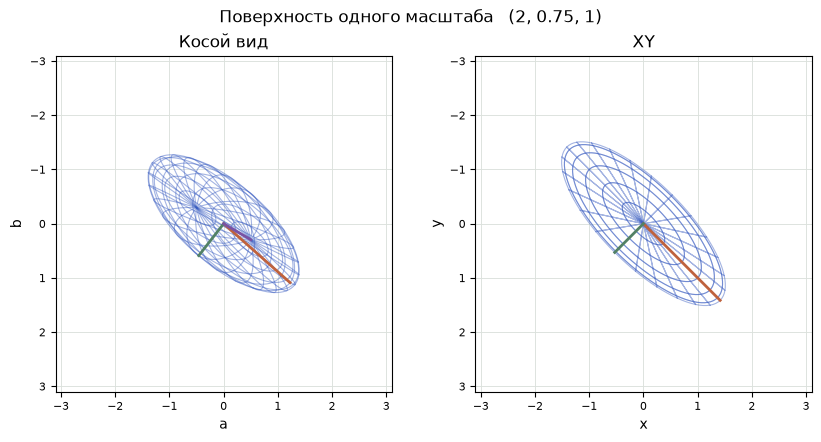

In [4]:
fig = demos.ellipsoid_figure("ru")
plt.show()

## 3. Ось, угол и четыре числа поворота

Ось поворота — стрелка, которая при повороте остаётся на месте. Вокруг $z$ поворот на $90^\circ$ переносит правое направление $(1,0,0)$ в нижнее $(0,1,0)$. Три столбца $R$ — новые положения старых осей. Для этого поворота они равны $(0,1,0)$, $(-1,0,0)$ и $(0,0,1)$. Уже этого достаточно, чтобы умножать $R$ на любую точку.

Для обучения удобно хранить поворот четырьмя числами — **кватернионом**. Здесь их порядок $q=(w,x,y,z)$, скалярная часть первая. Эти $x,y,z$ принадлежат записи поворота и не задают положение центра. Если ось дана стрелкой $a=(0,0,2)$, сначала делим её на длину $\sqrt{0^2+0^2+2^2}=2$. Получается единичная ось $n=(0,0,1)$. Нулевая стрелка не задаёт направления. Из оси и угла $\theta$ строятся

$$
w=\cos(\theta/2),\qquad (x,y,z)=n\sin(\theta/2).
$$

Для $\theta=90^\circ$ в половине угла $45^\circ$. Косинус и синус равны $\sqrt{2}/2\approx0.7071$. Выходит $q=(0.7071,0,0,0.7071)$. Квадраты четырёх чисел в сумме дают 1. Если при обучении пришло $(2,0,0,2)$, перед поворотом все компоненты делятся на длину $\sqrt{2^2+2^2}=\sqrt{8}$. Получается та же единичная четвёрка. Для $(0,0,0,0)$ делить не на что.

Почему угол делится пополам? Для оси $z$ действие на правую единичную стрелку записывается как $(w^2-z^2,\,2wz,\,0)$. Пусть $w=\cos t$ и $z=\sin t$. Тогда по формулам двойного угла это $(\cos(2t),\sin(2t),0)$ — поворот уже на $2t$. Чтобы получить угол $\theta$, в запись кладут $t=\theta/2$. В нашем примере даётся $(0.5-0.5,\;2\cdot0.7071^2,\;0)\approx(0,1,0)$, как в чертеже.

In [5]:
q = geo.axis_angle_quaternion([0,0,2], 90)
R = geo.quaternion_matrix(q)
print("q =", q, "\nR =\n", R, "\nR (1,0,0) =", R @ [1,0,0])
np.testing.assert_allclose(R, geo.quaternion_matrix([2,0,0,2]), atol=1e-14)

q = [0.7071 0.     0.     0.7071] 
R =
 [[ 0. -1.  0.]
 [ 1.  0.  0.]
 [ 0.  0.  1.]] 
R (1,0,0) = [0. 1. 0.]


## 4. От кватерниона к матрице формы

Для любой единичной четвёрки три новых оси собираются по одним правилам. Первая строка ниже даёт горизонтальные компоненты трёх осей. Чтобы узнать горизонтальную координату повёрнутой точки, каждое число строки умножается на соответствующую координату точки, затем три произведения складываются.

$$
R=\begin{bmatrix}
1-2(y^2+z^2)&2(xy-zw)&2(xz+yw)\\
2(xy+zw)&1-2(x^2+z^2)&2(yz-xw)\\
2(xz-yw)&2(yz+xw)&1-2(x^2+y^2)
\end{bmatrix}.
$$

Здесь $xy$ значит $x\cdot y$. Например, при $q=(\sqrt{2}/2,0,0,\sqrt{2}/2)$ первый элемент равен $1-2(0+1/2)=0$, второй $2(0-1/2)=-1$, третий 0. Отсюда у повёрнутой точки $(1.2,0.6,0)$ горизонтальная координата $0\cdot1.2-1\cdot0.6+0=-0.6$ м. Если поменять знаки сразу у всех четырёх компонентов $q$, все попарные произведения и квадраты останутся прежними. $q$ и $-q$ описывают один поворот.

Масштабы формы положительны. В собственных осях их квадраты стоят на диагонали ковариации: $D=\mathrm{diag}(4,0.5625,1)$ в м². Этот $D$ — матрица, в отличие от скалярной величины $D^2$ в расчёте веса выше. Если из единичной сферы в эллипсоид ведёт $M=RS$, то ковариация меняется с двух сторон: $\Sigma=MM^{\mathsf T}=RDR^{\mathsf T}$. Число $\Sigma_{xy}$ — скалярное произведение первой и второй строк $M$. Оно показывает, насколько одни и те же собственные смещения двигают точку вдоль обеих мировых осей.

Например, при $45^\circ$ вокруг $z$ обозначим $c=\cos45^\circ=s=\sin45^\circ$. Первые две строки $M$ равны $(2c,-0.75s,0)$ и $(2s,0.75c,0)$. Отсюда $\Sigma_{xx}=4c^2+0.5625s^2=2.28125$, $\Sigma_{yy}=2.28125$, а $\Sigma_{xy}=4cs-0.5625sc=1.71875$ м². Удлинение идёт одновременно вправо и вниз, поэтому перекрёстный элемент положителен. При $90^\circ$ он исчезает, а два поперечных квадрата просто меняются местами.

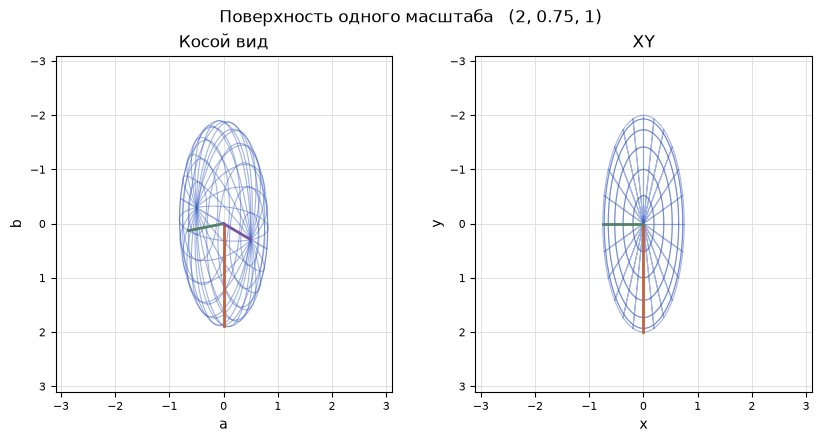

In [6]:
fig = demos.ellipsoid_figure("ru", angle=90)
plt.show()

In [7]:
q45 = geo.axis_angle_quaternion([0,0,1], 45)
cov = geo.covariance_3d(scales, q45)
print("Σ =\n", cov)
delta = geo.quaternion_matrix(q45) @ (scales*h)
relative_squared = delta @ np.linalg.solve(cov, delta)
print("G on shell =", np.exp(-relative_squared/2))
np.testing.assert_allclose(relative_squared, 1)

Σ =
 [[2.2812 1.7188 0.    ]
 [1.7188 2.2813 0.    ]
 [0.     0.     1.    ]]
G on shell = 0.6065306597126333


## 5. Где у формы ломается геометрия

**Опыт.** У эллипсоида масштабы $(2,1,1)$. Сначала он вращается вокруг длинной оси $x$, затем отдельно вокруг $z$. В каком случае силуэт вдоль $z$ изменится?

<details>
<summary>Разбор</summary>

Для первого поворота два поперечных размера совпадают. Их круг можно повернуть без изменения поверхности. Матрица остаётся $\mathrm{diag}(4,1,1)$. Поворот вокруг $z$ на $90^\circ$ переводит длинное направление в $y$ и даёт $\mathrm{diag}(1,4,1)$. Вместо горизонтального эллипса виден вертикальный.

</details>

**Плоское облачко.** Что случится при попытке задать $s_z=0$?

<details>
<summary>Разбор</summary>

Третье смещение придётся делить на ноль. В матрице формы появится направление нулевой ширины, по которому нельзя восстановить исходное смещение. Плоский диск сам по себе осмыслен, но вычисление веса полноценной объёмной гауссианы требует трёх ненулевых масштабов. Поэтому в опыте нижняя граница положительна.

</details>

Та же запись оси и половинного угла приводится в [справке SciPy по кватернионам](https://docs.scipy.org/doc/scipy/reference/generated/scipy.spatial.transform.Rotation.from_quat.html). При обмене данными имеет значение, где находится скалярная часть.